In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

from google.colab import files

In [2]:
uploaded = files.upload()

df = pd.read_csv('standardized_dataset.csv')

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)

df.head()

Saving standardized_dataset.csv to standardized_dataset (1).csv
Dataset loaded successfully!
Original dataset shape: (5043, 154)


,director_name,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,actor_1_name,movie_title,...,country_Sweden,country_Switzerland,country_Taiwan,country_Thailand,country_Turkey,country_UK,country_USA,country_United Arab Emirates,country_West Germany,color_Color
0,James Cameron,2.814615,-0.241750,0.127161,Joel David Moore,-0.369901,760505847.0,Action|Adventure|Fantasy|Sci-Fi,CCH Pounder,Avatar,...,0,0,0,0,0,0,1,0,0,1
1,Gore Verbinski,2.456882,-0.039622,0.214449,Orlando Bloom,2.228320,309404152.0,Action|Adventure|Fantasy,Johnny Depp,Pirates of the Caribbean: At World's End,...,0,0,0,0,0,0,1,0,0,1
2,Sam Mendes,1.622174,-0.241750,-0.290615,Rory Kinnear,0.296310,200074175.0,Action|Adventure|Thriller,Christoph Waltz,Spectre,...,0,0,0,0,0,1,0,0,0,1
3,Christopher Nolan,2.258142,7.656689,13.458069,Christian Bale,1.362246,448130642.0,Action|Thriller,Tom Hardy,The Dark Knight Rises,...,0,0,0,0,0,0,1,0,0,1
4,Doug Walker,-0.166488,-0.194719,-0.163897,Rob Walker,-0.427795,NaN,Documentary,Doug Walker,Star Wars: Episode VII - The Force Awakens ...,...,0,0,0,0,0,0,1,0,0,1


In [3]:
# Separate target variable
y = df['gross']

# Remove gross from input dataset
X = df.drop(columns=['gross'])

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (5043, 153)
Target variable shape: (5043,)


In [4]:
# Select numerical columns only
X = X.select_dtypes(include=['int64', 'float64'])

print("Numerical dataset shape:", X.shape)

print("Remaining columns:")
print(X.columns.tolist())

Numerical dataset shape: (5043, 146)
Remaining columns:
['duration', 'director_facebook_likes', 'actor_3_facebook_likes', 'actor_1_facebook_likes', 'cast_total_facebook_likes', 'facenumber_in_poster', 'budget', 'title_year', 'actor_2_facebook_likes', 'aspect_ratio', 'movie_facebook_likes', 'release_decade', 'number_of_genres', 'duration_category', 'budget_category', 'number_of_plot_keywords', 'cast_popularity', 'movie_age', 'production_country_count', 'content_rating_G', 'content_rating_GP', 'content_rating_M', 'content_rating_NC-17', 'content_rating_Not Rated', 'content_rating_PG', 'content_rating_PG-13', 'content_rating_Passed', 'content_rating_R', 'content_rating_TV-14', 'content_rating_TV-G', 'content_rating_TV-MA', 'content_rating_TV-PG', 'content_rating_TV-Y', 'content_rating_TV-Y7', 'content_rating_Unrated', 'content_rating_X', 'language_Arabic', 'language_Aramaic', 'language_Bosnian', 'language_Cantonese', 'language_Chinese', 'language_Czech', 'language_Danish', 'language_Dari'

In [5]:
# Replace infinite values with NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns containing only missing values
X = X.dropna(axis=1, how='all')

# Fill missing values using median
imputer = SimpleImputer(strategy='median')

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("Missing values handled successfully!")

print("Missing values remaining:", X.isnull().sum().sum())

print("Final dataset shape:", X.shape)

Missing values handled successfully!
Missing values remaining: 0
Final dataset shape: (5043, 146)


In [6]:
# Remove columns with zero variance
X = X.loc[:, X.nunique() > 1]

print("Dataset shape after removing constant features:", X.shape)

Dataset shape after removing constant features: (5043, 145)


In [7]:
pca = PCA()

X_pca = pca.fit_transform(X)

print("PCA completed successfully!")

print("Original number of features:", X.shape[1])

print("Number of principal components:", X_pca.shape[1])

PCA completed successfully!
Original number of features: 145
Number of principal components: 145


In [8]:
explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

variance_df = pd.DataFrame({
    'Principal Component': range(1, len(explained_variance) + 1),
    'Explained Variance': explained_variance,
    'Cumulative Variance': cumulative_variance
})

print(variance_df)

     Principal Component  Explained Variance  Cumulative Variance
0                      1        2.147321e-01             0.214732
1                      2        1.593965e-01             0.374129
2                      3        1.021289e-01             0.476258
3                      4        6.661045e-02             0.542868
4                      5        5.522744e-02             0.598095
..                   ...                 ...                  ...
140                  141        6.266819e-19             1.000000
141                  142        6.689457e-21             1.000000
142                  143        0.000000e+00             1.000000
143                  144        0.000000e+00             1.000000
144                  145        0.000000e+00             1.000000

[145 rows x 3 columns]


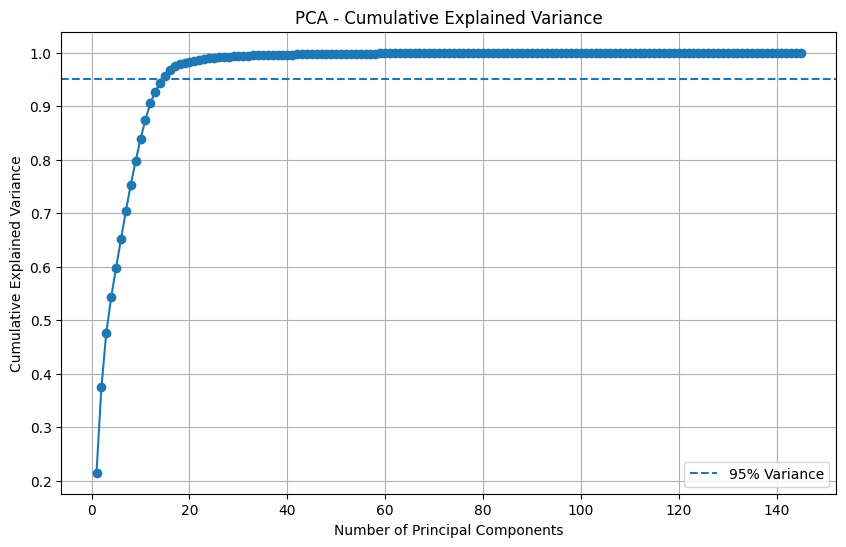

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(y=0.95, linestyle='--', label='95% Variance')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')

plt.title('PCA - Cumulative Explained Variance')

plt.legend()
plt.grid()

plt.show()

In [10]:
# Find the number of components required for 95% variance
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of components selected:", n_components)

print(
    "Total variance retained:",
    round(cumulative_variance[n_components - 1] * 100, 2),
    "%"
)

Number of components selected: 15
Total variance retained: 95.57 %


In [11]:
# Apply PCA with selected components
pca_final = PCA(n_components=n_components)

X_reduced = pca_final.fit_transform(X)

# Convert into DataFrame
pca_df = pd.DataFrame(
    X_reduced,
    columns=[f'PC{i+1}' for i in range(n_components)]
)

# Add original target variable
pca_df['gross'] = y.reset_index(drop=True)

print("PCA transformation completed!")

print("Original feature count:", X.shape[1])

print("Reduced feature count:", n_components)

print("Final dataset shape:", pca_df.shape)

pca_df.head()

PCA transformation completed!
Original feature count: 145
Reduced feature count: 15
Final dataset shape: (5043, 16)


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,gross
0,1.092703,-0.405484,3.837326,0.116049,-0.595945,0.498601,0.134162,0.157632,-0.767187,0.084370,0.536613,0.348679,-0.175691,-0.439397,-0.864804,760505847.0
1,4.099777,-1.587068,1.062382,0.067204,-1.760890,1.842817,0.133070,0.667983,-0.326272,0.287283,-0.752192,0.545707,-0.120800,-0.538285,-0.656269,309404152.0
2,2.296529,0.831743,3.552764,-0.335591,0.061303,0.249403,-0.106573,0.269020,-0.244184,1.596260,2.628234,0.732858,0.047728,-0.351859,-0.132918,200074175.0
3,13.940466,-3.229470,2.800851,-2.565933,10.884766,-4.114651,-2.180997,2.299913,-1.369925,-0.906790,0.235065,-0.869056,-4.711812,0.407099,-0.777464,448130642.0
4,-1.300328,1.582147,-1.164683,-2.450296,0.617681,2.068219,0.016359,1.272260,-1.557879,-2.240776,0.952125,0.738833,-0.039699,0.239675,0.154189,NaN


In [12]:
pca_df.to_csv('movie_dataset_pca.csv', index=False)

files.download('movie_dataset_pca.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>